# Gaussian blur and five-point derivatives

Use this notebook to analyze the structure tensor of different silicones. The structure tensor is independent of motion a single image per silicone is enough.

In [1]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

IMAGE_DIR = Path.cwd() if Path.cwd().name == "optical_flow" else Path.cwd() / "optical_flow"
IMAGE_NAME = "8.png" #change this to your silicone image

img = cv2.imread(str(IMAGE_DIR / IMAGE_NAME), cv2.IMREAD_GRAYSCALE)
img = img.astype(np.float32) / 255.0


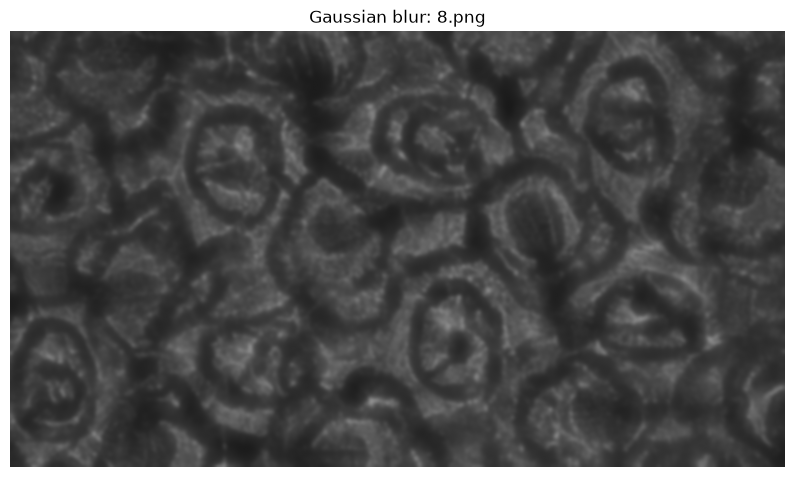

In [3]:
smooth = cv2.GaussianBlur(img, (0, 0), sigmaX=10, sigmaY=10)
# play around with the sigmaX and sigmaY values to see how it affects the smoothing,
# this has a very big effect on the computed gradients

plt.figure(figsize=(10, 6))
plt.imshow(smooth, cmap="gray", vmin=0, vmax=1)
plt.title(f"Gaussian blur: {IMAGE_NAME}")
plt.axis("off")
plt.show()


The following cell will show the gradients in x and y after significant blurring to remove finer details and focus the gradient on broader structures.

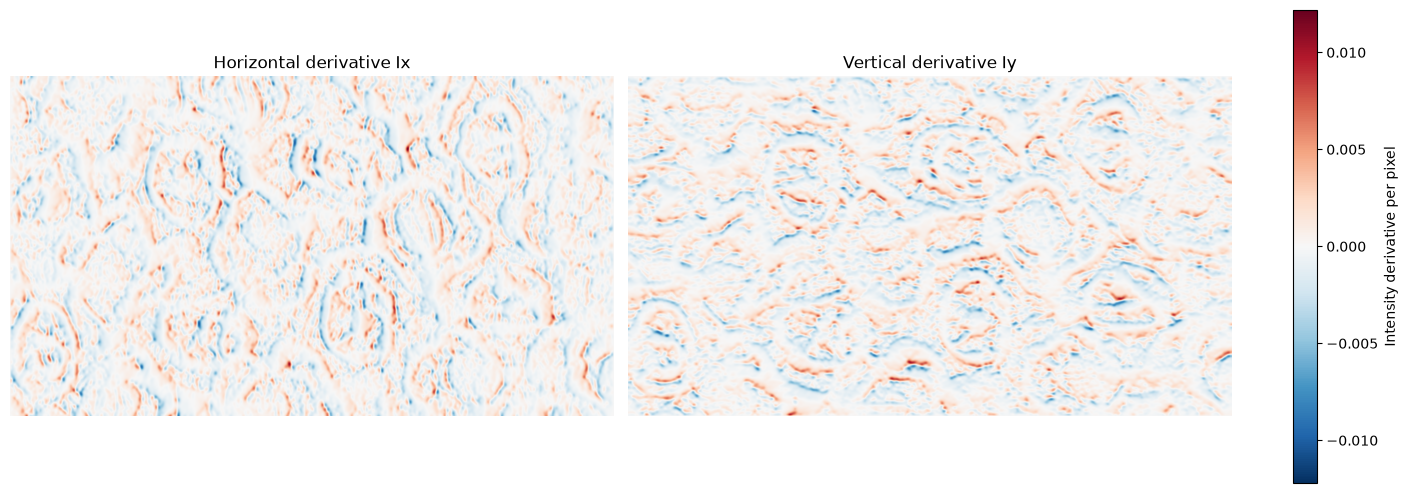

In [4]:
kernel = np.array([1, -8, 0, 8, -1], dtype=np.float32) / 12
# gaussian gradient kernel
Ix = cv2.filter2D(smooth, -1, kernel.reshape(1, 5))
Iy = cv2.filter2D(smooth, -1, kernel.reshape(5, 1))

limit = max(np.abs(Ix).max(), np.abs(Iy).max())
fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)
for ax, derivative, title in zip(axes, [Ix, Iy], ["Horizontal derivative Ix", "Vertical derivative Iy"]):
    plot = ax.imshow(derivative, cmap="RdBu_r", vmin=-limit, vmax=limit)
    ax.set_title(title)
    ax.axis("off")
fig.colorbar(plot, ax=axes, label="Intensity derivative per pixel", shrink=0.8)
plt.show()


red indicates rising pixel value, blue indicates falling pixel value

## Structure tensor

Lets analyze the components of the strucute tensor

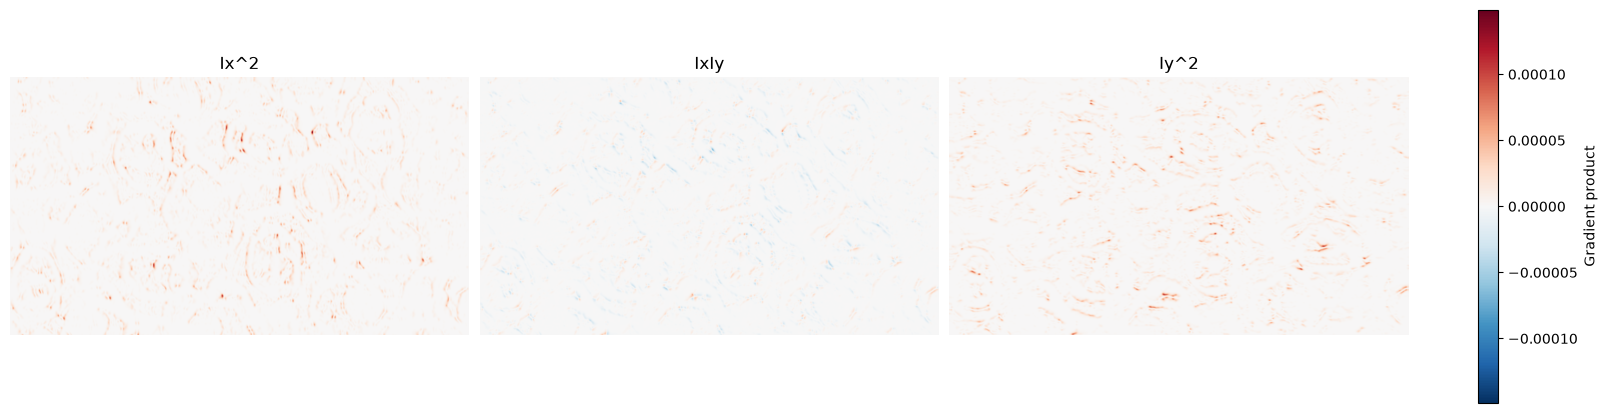

In [5]:
Ix2, Ixy, Iy2 = Ix * Ix, Ix * Iy, Iy * Iy
limit = max(Ix2.max(), np.abs(Ixy).max(), Iy2.max())
fig, axes = plt.subplots(1, 3, figsize=(16, 5), constrained_layout=True)
for ax, values, title in zip(axes, [Ix2, Ixy, Iy2], ["Ix^2", "IxIy", "Iy^2"]):
    plot = ax.imshow(values, cmap="RdBu_r", vmin=-limit, vmax=limit)
    ax.set_title(title)
    ax.axis("off")
fig.colorbar(plot, ax=axes, label="Gradient product", shrink=0.8)
plt.show()


you can already tell there are few regions that have large gradient in both x *and* y

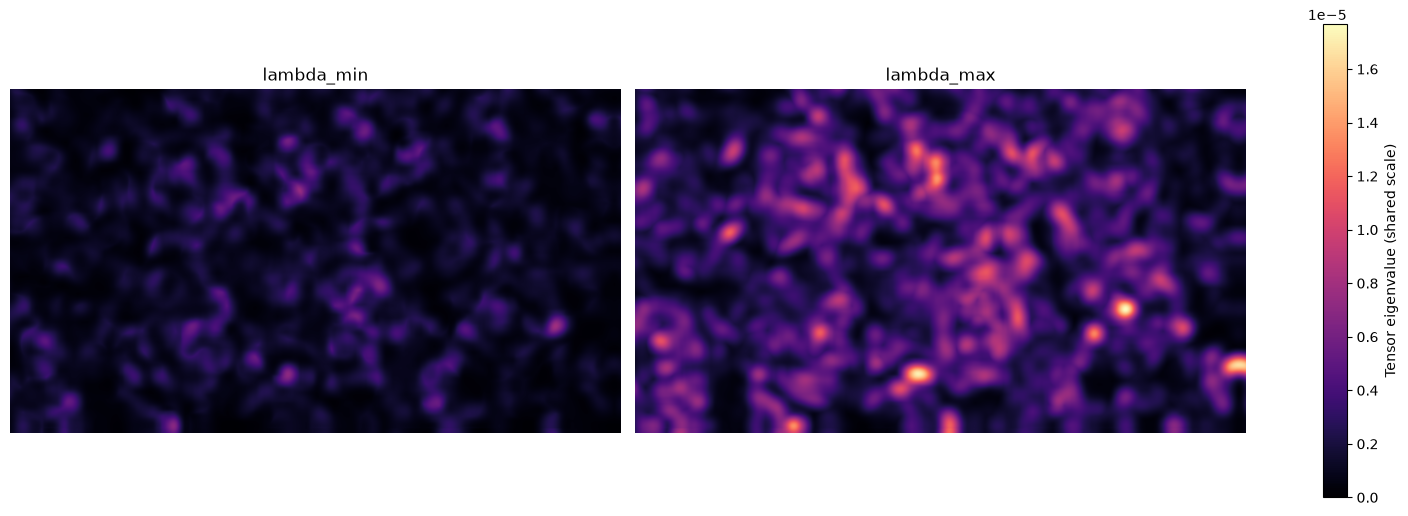

In [7]:
window_size = 200 # very big effect on the computed eigenvalues, play around with this value to see how it affects the results
# adapt the sigma value of the Gaussian kernel to the window size
weights = cv2.getGaussianKernel(window_size, 50, cv2.CV_32F).ravel()
weights /= weights.sum()

Axx = cv2.sepFilter2D(Ix2, -1, weights, weights, anchor=(50, 50))
Axy = cv2.sepFilter2D(Ixy, -1, weights, weights, anchor=(50, 50))
Ayy = cv2.sepFilter2D(Iy2, -1, weights, weights, anchor=(50, 50))
trace = Axx + Ayy
separation = np.hypot(Axx - Ayy, 2 * Axy)
lambda_min = np.maximum((trace - separation) / 2, 0)
lambda_max = (trace + separation) / 2

fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)
for ax, values, title in zip(axes, [lambda_min, lambda_max], ["lambda_min", "lambda_max"]):
    plot = ax.imshow(values, cmap="magma", vmin=0, vmax=lambda_max.max())
    ax.set_title(title)
    ax.axis("off")
fig.colorbar(plot, ax=axes, label="Tensor eigenvalue (shared scale)", shrink=0.8)
plt.show()


We assume here that the 500x500 window will move in a consitent direction. Which is a reasonable assumption imo. Helps to integrate gradient signal over larger region to make the smallest eigenvalue larger.

Smallest lambda_min at (x, y)=(4298, 321): lambda_min=1.13738736e-07, lambda_max=6.13624081e-07
Largest lambda_min at (x, y)=(4114, 1788): lambda_min=7.87446334e-06, lambda_max=1.00958969e-05


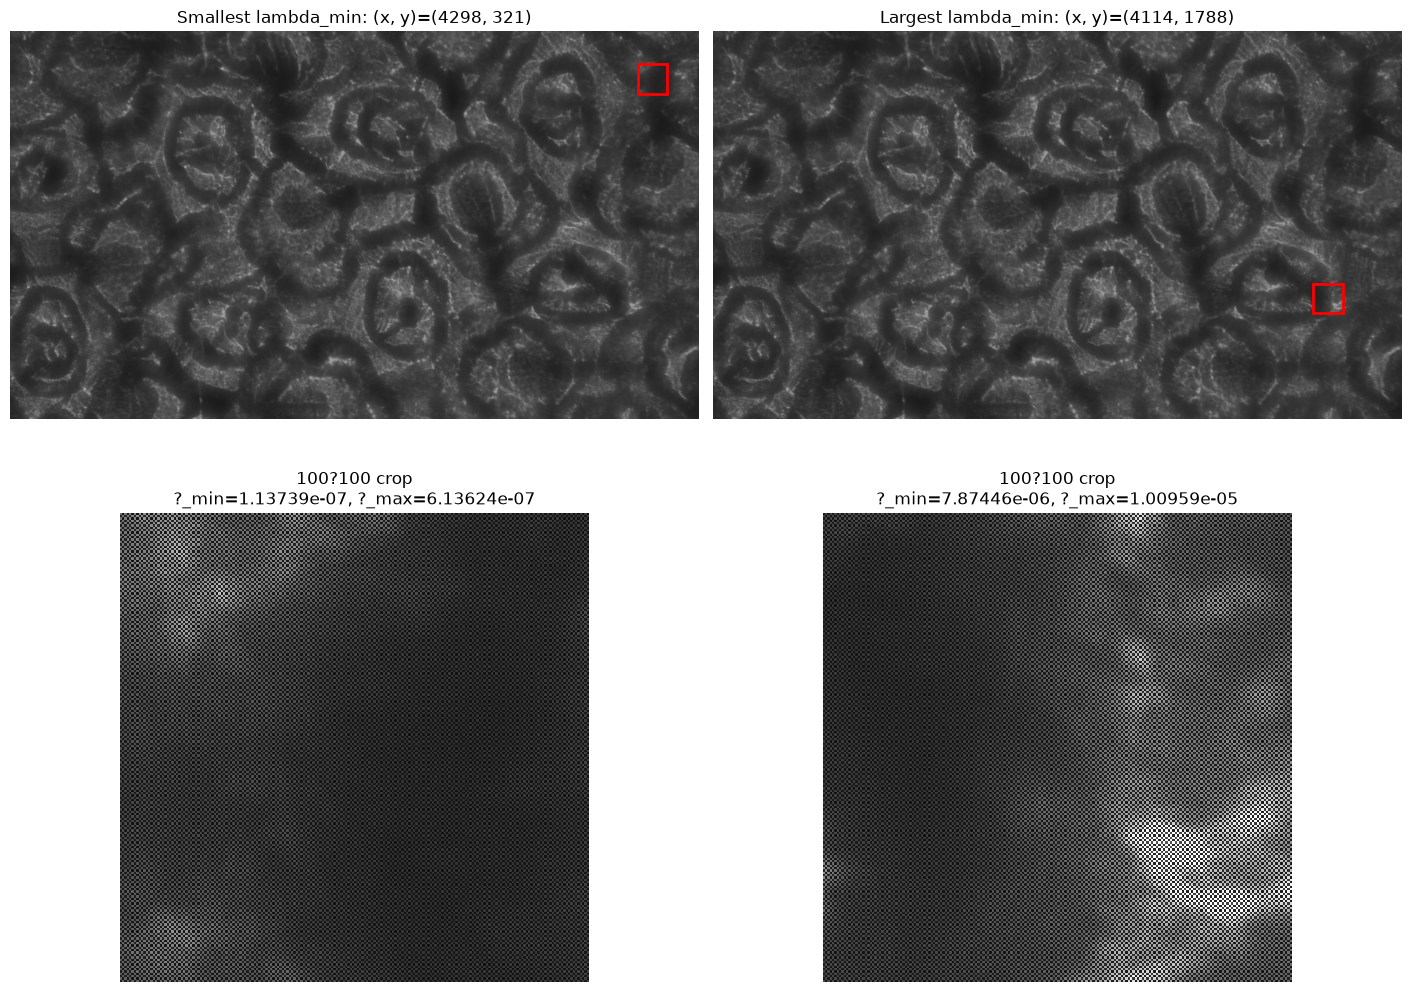

In [8]:
from matplotlib.patches import Rectangle

half = window_size // 2
height, width = img.shape
valid = lambda_min[half:height - half + 1, half:width - half + 1]
locations = [np.unravel_index(i, valid.shape) for i in [valid.argmin(), valid.argmax()]]
locations = [(y + half, x + half) for y, x in locations]
fig, axes = plt.subplots(2, 2, figsize=(14, 10), constrained_layout=True)
for column, ((y, x), label) in enumerate(zip(locations, ["Smallest lambda_min", "Largest lambda_min"])):
    x0, y0 = x - half, y - half
    axes[0, column].imshow(img, cmap="gray", vmin=0, vmax=1)
    axes[0, column].add_patch(Rectangle((x0 - 0.5, y0 - 0.5), window_size, window_size,
                                       fill=False, edgecolor="red", linewidth=2))
    axes[0, column].set_title(f"{label}: (x, y)=({x}, {y})")
    axes[1, column].imshow(img[y0:y0 + window_size, x0:x0 + window_size],
                           cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    axes[1, column].set_title(f"100?100 crop\n?_min={lambda_min[y, x]:.6g}, ?_max={lambda_max[y, x]:.6g}")
    print(f"{label} at (x, y)=({x}, {y}): lambda_min={lambda_min[y, x]:.9g}, lambda_max={lambda_max[y, x]:.9g}")
for ax in axes.flat:
    ax.axis("off")
plt.show()


We show the patch that was used to compute a structure tensor that achieved the highest and the smallest minimum eigenvalue in a given structure tensor. 

Median lambda_min: 1.2203041e-06
Median lambda_max: 3.2987355e-06
Median ratio: 0.41424543


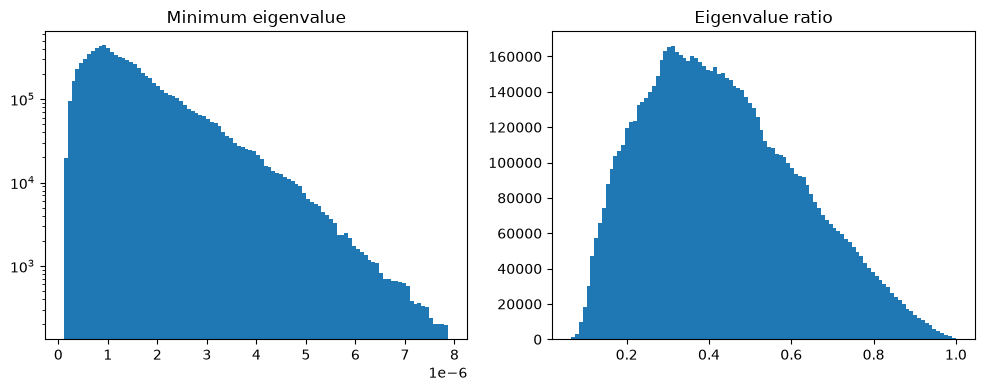

In [9]:
valid = np.s_[250:-250, 250:-250]

lmin = lambda_min[valid]
lmax = lambda_max[valid]

ratio = lmin / (lmax + 1e-12)

print("Median lambda_min:", np.median(lmin))
print("Median lambda_max:", np.median(lmax))
print("Median ratio:", np.median(ratio))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(lmin.ravel(), bins=100, log=True)
axes[0].set_title("Minimum eigenvalue")

axes[1].hist(ratio.ravel(), bins=100)
axes[1].set_title("Eigenvalue ratio")

plt.show()

A good distribution should have large minimum eigenvalues and a relatively balanced eigenvalue ratio (good gradients in both directions).